Libraries imported successfully!

Upload your dataset ZIP file


Saving archive.zip to archive.zip
Dataset extracted successfully!

Total images found: 128
Total annotation files found: 126

CLASS DISTRIBUTION
   Class  Image_Count
0    val           28
1  train          100


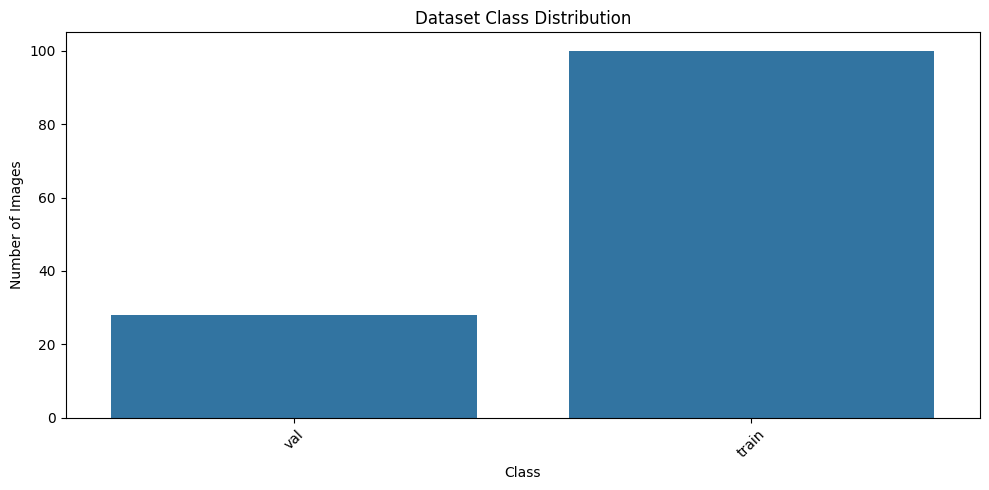


IMAGE QUALITY REPORT
              Image  Width  Height  Blur_Score Quality
0  000000000263.jpg    591     640      245.76    Good
1  000000000443.jpg    640     480      224.99    Good
2  000000000349.jpg    640     480      203.66    Good
3  000000000542.jpg    640     484     2026.19    Good
4  000000000151.jpg    480     640     9093.91    Good
5  000000000328.jpg    640     491     4405.91    Good
6  000000000009.jpg    640     480     1722.04    Good
7  000000000283.jpg    428     640      692.06    Good
8  000000000474.jpg    333     500     2207.72    Good
9  000000000531.jpg    640     480     1486.92    Good

Quality Summary:
Quality
Good      127
Blurry      1
Name: count, dtype: int64


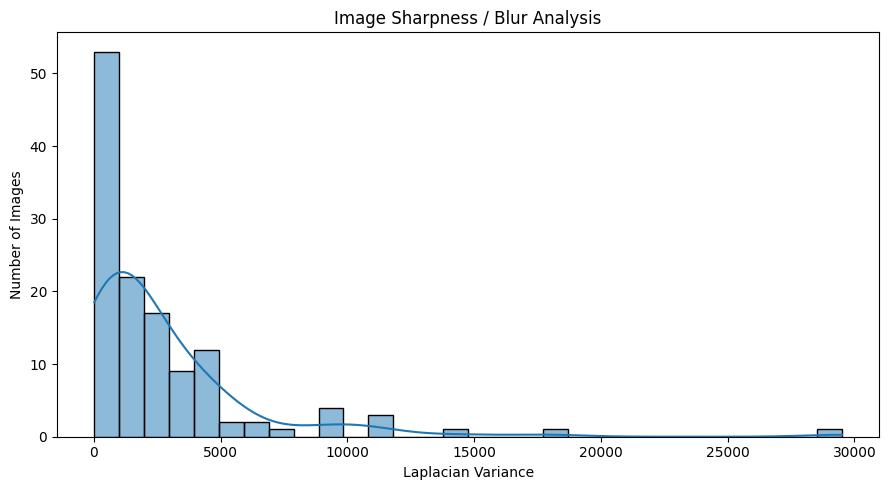

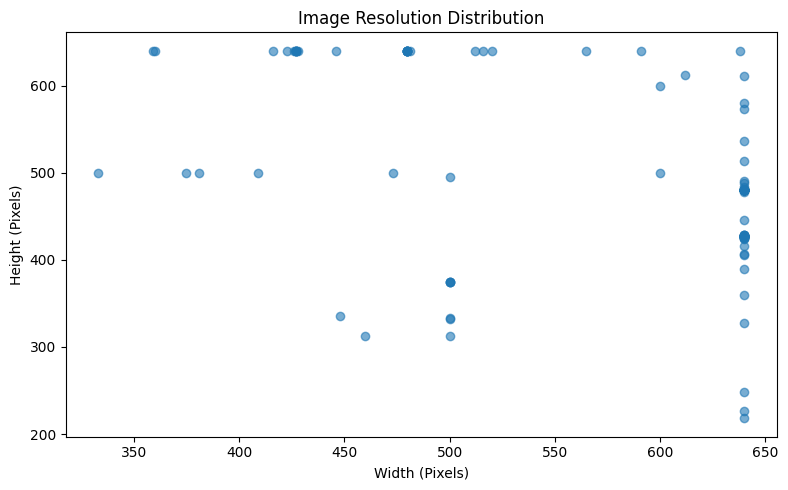


ANNOTATION VALIDATION REPORT
              Image Annotation Validation  Object_Count
0  000000000263.jpg    Present    Invalid             0
1  000000000443.jpg    Present      Valid             6
2  000000000349.jpg    Present      Valid             4
3  000000000542.jpg    Present      Valid            17
4  000000000151.jpg    Present    Invalid             1
5  000000000328.jpg    Present      Valid            11
6  000000000009.jpg    Present      Valid             8
7  000000000283.jpg    Present    Invalid             2
8  000000000474.jpg    Present      Valid             2
9  000000000531.jpg    Present      Valid            15

Annotation Summary:
Validation
Valid      93
Invalid    35
Name: count, dtype: int64


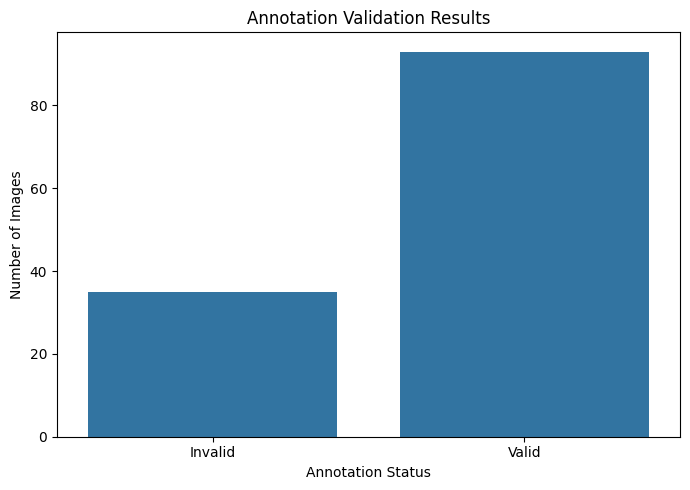


SAMPLE ANNOTATED IMAGES


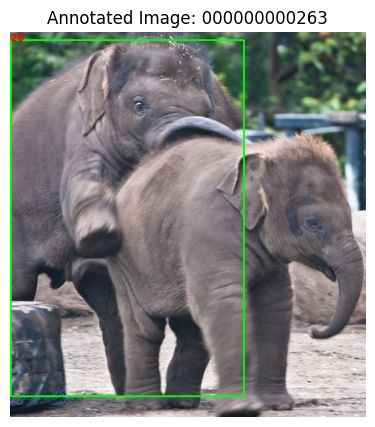

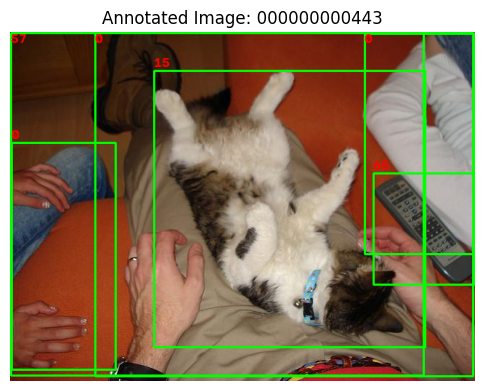

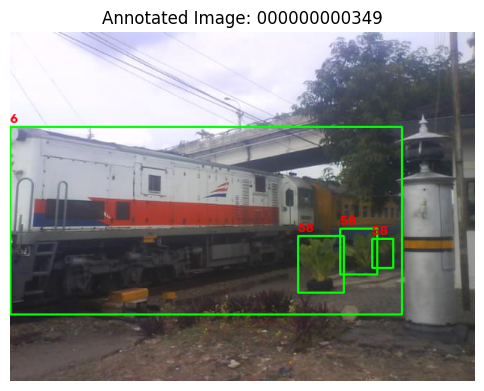

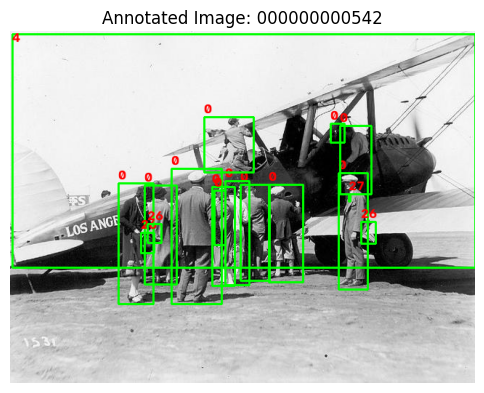

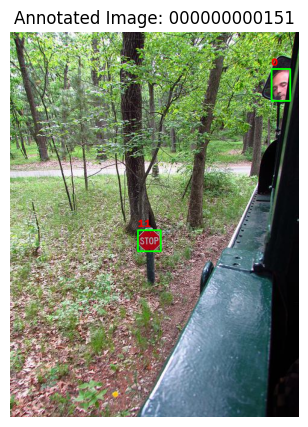



          FINAL DATASET AUDIT REPORT
Total Images: 128

CLASS DISTRIBUTION
Class  Image_Count
  val           28
train          100

IMAGE QUALITY
Good Images: 127
Blurry Images: 1
Corrupted Images: 0

ANNOTATION VALIDATION
Valid Annotations: 93
Invalid Annotations: 35
Missing Annotations: 2
       DATASET AUDIT COMPLETED SUCCESSFULLY

All reports saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXPERIMENT COMPLETED SUCCESSFULLY!


In [2]:

# ============================================================
# SKILL LAB EXPERIMENT
# DATASET AUDIT AND VISUALISATION
# Class Distribution, Image Quality and Annotation Validation
# ============================================================

# STEP 1: INSTALL AND IMPORT LIBRARIES

!pip -q install opencv-python-headless seaborn pandas pillow

import os
import cv2
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from collections import Counter

print("Libraries imported successfully!")


# STEP 2: UPLOAD DATASET ZIP FILE

print("\nUpload your dataset ZIP file")

uploaded = files.upload()

zip_file = next(
    (f for f in uploaded if f.lower().endswith('.zip')),
    None
)

if zip_file is None:
    raise ValueError("Please upload a ZIP file.")

dataset_path = "/content/dataset"

if os.path.exists(dataset_path):
    shutil.rmtree(dataset_path)

os.makedirs(dataset_path)

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")


# STEP 3: AUTOMATICALLY FIND IMAGE AND LABEL FOLDERS

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

image_files = []
label_files = {}

for root, dirs, files_list in os.walk(dataset_path):

    for filename in files_list:

        full_path = os.path.join(root, filename)

        if filename.lower().endswith(image_extensions):
            image_files.append(full_path)

        elif filename.lower().endswith('.txt'):
            label_files[
                os.path.splitext(filename)[0]
            ] = full_path

print("\nTotal images found:", len(image_files))
print("Total annotation files found:", len(label_files))

if len(image_files) == 0:
    raise ValueError("No images found in the uploaded dataset.")


# STEP 4: CLASS DISTRIBUTION ANALYSIS

class_counts = Counter()

for image_path in image_files:

    relative_path = os.path.relpath(
        image_path, dataset_path
    )

    parts = relative_path.split(os.sep)

    # Use the parent folder as class name
    class_name = parts[-2] if len(parts) > 1 else "Unknown"

    class_counts[class_name] += 1

class_df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Image_Count"]
)

print("\nCLASS DISTRIBUTION")
print(class_df)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_df,
    x="Class",
    y="Image_Count"
)

plt.title("Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("class_distribution.png")
plt.show()


# STEP 5: IMAGE QUALITY ANALYSIS

quality_results = []

for image_path in image_files:

    filename = os.path.basename(image_path)

    try:

        image = cv2.imread(image_path)

        if image is None:
            quality_results.append({
                "Image": filename,
                "Width": 0,
                "Height": 0,
                "Blur_Score": 0,
                "Quality": "Corrupted"
            })
            continue

        height, width = image.shape[:2]

        gray = cv2.cvtColor(
            image, cv2.COLOR_BGR2GRAY
        )

        blur_score = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        if blur_score < 100:
            status = "Blurry"
        else:
            status = "Good"

        quality_results.append({
            "Image": filename,
            "Width": width,
            "Height": height,
            "Blur_Score": round(blur_score, 2),
            "Quality": status
        })

    except Exception:

        quality_results.append({
            "Image": filename,
            "Width": 0,
            "Height": 0,
            "Blur_Score": 0,
            "Quality": "Corrupted"
        })

quality_df = pd.DataFrame(quality_results)

print("\nIMAGE QUALITY REPORT")
print(quality_df.head(10))

print("\nQuality Summary:")
print(quality_df["Quality"].value_counts())


# STEP 6: BLUR SCORE VISUALIZATION

plt.figure(figsize=(9, 5))

sns.histplot(
    data=quality_df,
    x="Blur_Score",
    bins=30,
    kde=True
)

plt.title("Image Sharpness / Blur Analysis")
plt.xlabel("Laplacian Variance")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig("image_quality.png")
plt.show()


# STEP 7: IMAGE RESOLUTION VISUALIZATION

valid_quality = quality_df[
    quality_df["Width"] > 0
]

plt.figure(figsize=(8, 5))

plt.scatter(
    valid_quality["Width"],
    valid_quality["Height"],
    alpha=0.6
)

plt.title("Image Resolution Distribution")
plt.xlabel("Width (Pixels)")
plt.ylabel("Height (Pixels)")
plt.tight_layout()
plt.savefig("image_resolution.png")
plt.show()


# STEP 8: YOLO ANNOTATION VALIDATION

annotation_results = []

for image_path in image_files:

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    label_path = label_files.get(image_name)

    if label_path is None:

        annotation_results.append({
            "Image": os.path.basename(image_path),
            "Annotation": "Missing",
            "Validation": "Invalid",
            "Object_Count": 0
        })

        continue

    valid = True
    object_count = 0

    try:

        with open(label_path, "r") as file:

            lines = file.readlines()

            for line in lines:

                if not line.strip():
                    continue

                values = line.strip().split()

                if len(values) != 5:
                    valid = False
                    break

                try:
                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                except ValueError:
                    valid = False
                    break

                if class_id < 0:
                    valid = False
                    break

                if not np.all(
                    np.isfinite([x, y, w, h])
                ):
                    valid = False
                    break

                if not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1 and
                    x - w/2 >= 0 and
                    x + w/2 <= 1 and
                    y - h/2 >= 0 and
                    y + h/2 <= 1
                ):
                    valid = False
                    break

                object_count += 1

    except Exception:
        valid = False

    annotation_results.append({
        "Image": os.path.basename(image_path),
        "Annotation": "Present",
        "Validation": "Valid" if valid else "Invalid",
        "Object_Count": object_count
    })

annotation_df = pd.DataFrame(annotation_results)

print("\nANNOTATION VALIDATION REPORT")
print(annotation_df.head(10))

print("\nAnnotation Summary:")
print(annotation_df["Validation"].value_counts())


# STEP 9: ANNOTATION STATUS GRAPH

plt.figure(figsize=(7, 5))

sns.countplot(
    data=annotation_df,
    x="Validation"
)

plt.title("Annotation Validation Results")
plt.xlabel("Annotation Status")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig("annotation_validation.png")
plt.show()


# STEP 10: VISUALIZE BOUNDING BOXES

print("\nSAMPLE ANNOTATED IMAGES")

shown = 0

for image_path in image_files:

    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    label_path = label_files.get(image_name)

    if label_path is None:
        continue

    image = cv2.imread(image_path)

    if image is None:
        continue

    height, width = image.shape[:2]

    with open(label_path, "r") as file:

        for line in file:

            values = line.strip().split()

            if len(values) != 5:
                continue

            try:
                class_id, x, y, bw, bh = map(
                    float, values
                )
            except ValueError:
                continue

            if not np.all(np.isfinite(
                [class_id, x, y, bw, bh]
            )):
                continue

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < bw <= 1 and
                0 < bh <= 1 and
                x-bw/2 >= 0 and
                x+bw/2 <= 1 and
                y-bh/2 >= 0 and
                y+bh/2 <= 1
            ):
                continue

            x1 = int((x - bw/2) * width)
            y1 = int((y - bh/2) * height)
            x2 = int((x + bw/2) * width)
            y2 = int((y + bh/2) * height)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                image,
                str(int(class_id)),
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 0, 255),
                2
            )

    image = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title("Annotated Image: " + image_name)
    plt.axis("off")
    plt.show()

    shown += 1

    if shown == 5:
        break

if shown == 0:
    print("No images with annotation files found.")


# STEP 11: GENERATE FINAL AUDIT REPORT

total_images = len(image_files)

good_images = (
    quality_df["Quality"] == "Good"
).sum()

blurry_images = (
    quality_df["Quality"] == "Blurry"
).sum()

corrupted_images = (
    quality_df["Quality"] == "Corrupted"
).sum()

valid_annotations = (
    annotation_df["Validation"] == "Valid"
).sum()

invalid_annotations = (
    annotation_df["Validation"] == "Invalid"
).sum()

missing_annotations = (
    annotation_df["Annotation"] == "Missing"
).sum()

print("\n")
print("=" * 55)
print("          FINAL DATASET AUDIT REPORT")
print("=" * 55)

print("Total Images:", total_images)

print("\nCLASS DISTRIBUTION")
print(class_df.to_string(index=False))

print("\nIMAGE QUALITY")
print("Good Images:", good_images)
print("Blurry Images:", blurry_images)
print("Corrupted Images:", corrupted_images)

print("\nANNOTATION VALIDATION")
print("Valid Annotations:", valid_annotations)
print("Invalid Annotations:", invalid_annotations)
print("Missing Annotations:", missing_annotations)

print("=" * 55)
print("       DATASET AUDIT COMPLETED SUCCESSFULLY")
print("=" * 55)


# STEP 12: SAVE REPORTS

output_folder = "/content/Dataset_Audit_Reports"

os.makedirs(output_folder, exist_ok=True)

class_df.to_csv(
    output_folder + "/class_distribution.csv",
    index=False
)

quality_df.to_csv(
    output_folder + "/image_quality_report.csv",
    index=False
)

annotation_df.to_csv(
    output_folder + "/annotation_validation.csv",
    index=False
)

# Save final summary
summary = pd.DataFrame({
    "Metric": [
        "Total Images",
        "Good Images",
        "Blurry Images",
        "Corrupted Images",
        "Valid Annotations",
        "Invalid Annotations",
        "Missing Annotations"
    ],
    "Count": [
        total_images,
        good_images,
        blurry_images,
        corrupted_images,
        valid_annotations,
        invalid_annotations,
        missing_annotations
    ]
})

summary.to_csv(
    output_folder + "/final_audit_summary.csv",
    index=False
)

# Copy generated graphs
for filename in [
    "class_distribution.png",
    "image_quality.png",
    "image_resolution.png",
    "annotation_validation.png"
]:

    shutil.copy(
        filename,
        output_folder
    )

# Create ZIP report
shutil.make_archive(
    "/content/Dataset_Audit_Reports",
    "zip",
    output_folder
)

print("\nAll reports saved successfully!")

# STEP 13: DOWNLOAD FINAL REPORT

files.download(
    "/content/Dataset_Audit_Reports.zip"
)

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
